# Практическая работа №1: Линейные дискретные системы и преобразование Фурье

## Цель работы
Изучить математическое описание линейных дискретных систем и дискретного преобразования Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины.

## Постановка задачи
Выполнить программную реализацию линейных дискретных систем, а также применить ДПФ для анализа периодических последовательностей и последовательностей конечной длины. Полученные результаты содержательно проинтерпретировать.

## Основные теоретические положения

Линейная дискретная система с постоянными коэффициентами описывается разностным уравнением:
$$\sum_{k=0}^{K} a_k\, y(n-k) = \sum_{i=0}^{I} b_i\, x(n-i), \qquad a_0 = 1.$$

Импульсная характеристика -- это реакция системы на единичный импульс, т.е. на воздействие $x = [1, 0, 0, 0, 0, ...]$

Передаточная функция $H(z) = Y(z) / X(z)$ задана в z-области и является z-изображением импульсной характеристики.

Выполнив некоторые преобразования, можно получить важный вывод:

$$
\begin{aligned}
H(z) = \frac{Y(z)}{X(z)} & = \frac{b_0 + b_1 \cdot z^{-1} + b_2 \cdot z^{-2}}{a_0 + a_1 \cdot z^{-1} + a_2 \cdot z^{-2}} \\
Y(z) & = \frac{b_0 + b_1 \cdot z^{-1} + b_2 \cdot z^{-2}}{a_0 + a_1 \cdot z^{-1} + a_2 \cdot z^{-2}} X(z) \\
Y(z) (a_0 + a_1 \cdot z^{-1} + a_2 \cdot z^{-2}) & = (b_0 + b_1 \cdot z^{-1} + b_2 \cdot z^{-2}) X(z) \\
a_0 Y(z) + a_1 Y(z) \cdot z^{-1} + a_2 Y(z) \cdot z^{-2} & = b_0 X(z) + b_1 X(z) \cdot z^{-1} + b_2 X(z) \cdot z^{-2} \\
\end{aligned}
$$

По табличным преобразованиям (свойство линейности и теорема о задержке) можно вернуться обратно во временную область:

$$
a_0 y(n) + a_1 y(n-1) + a_2 y(n-2) = b_0 x(n) + b_1 x(n-1) + b_2 x(n-2) \\
$$

Таким образом из передаточной функции получается разностное уравнение, задающее ЛДС. Из него можно получить рекуррентную формулу для вычисления реакции:

$$
y(n) = \frac{b_0 x(n) + b_1 x(n-1) + b_2 x(n-2) - a_1 y(n-1) - a_2 y(n-2)}{a_0}
$$

Вообще импульсная характеристика имеет бесконечную длину, но на практике часто ИХ стремится к нулю, поэтому достаточно вычислить ИХ некоторой фиксированной длины. Такой длины, что в контексте ошибок машинного округления потерянный хвост будет пренебрежительно мал.

Операция свёртки:
$$y(n) = \sum_{k=-\infty}^{\infty} h(k)\, x(n-k).$$

Имея импульсную характеристику и произвольное воздействие, можно вычислить реакцию на это воздействие с помощью операции свёртки. На практике пределы суммирования будут конечные.

Передаточную функцию можно также записать в виде:
$$H(z) = \frac{\prod_{i}(1 - z_i z^{-1})}{\prod_{k}(1 - p_k z^{-1})}$$
где нули $z_i$ -- корни числителя, полюсы $p_k$ -- корни знаменателя.

Критерий устойчивости: звено устойчиво тогда и только тогда, когда все полюсы лежат строго внутри единичной окружности ($|p_k| < 1$).

Дискретное преобразование Фурье периодической последовательности $x(n)$ с периодом $N$ и обратное преобразование:
$$X(k) = \sum_{n=0}^{N-1} x(n)\, e^{-j\frac{2\pi}{N} nk}, \qquad x(n) = \frac{1}{N}\sum_{k=0}^{N-1} X(k)\, e^{j\frac{2\pi}{N} nk}.$$

С помощью ДПФ можно получить амплитудный спектр $A_k = |X(k)|/N$ и фазовый спектр $\varphi_k = \arg X(k)$.
Они показывают, из каких компонент состоит сигнал (комплексные экспоненты определенной частоты, с определенной амплитудой и смещением по фазе)

Равенство Парсеваля (сохранение энергии при ДПФ):
$$\sum_{n=0}^{N-1} |x(n)|^2 = \frac{1}{N}\sum_{k=0}^{N-1} |X(k)|^2.$$

Восстановление аналогового сигнала по отсчётам ДПФ -- интерполяция рядом Фурье: отсчёту $X(k)$ соответствует комплексная экспонента $e^{j\frac{2\pi}{NT} kt}$. Отрицательным частотам $k \in [-N/2;\, -1]$ отвечают коэффициенты $X(N+k)$ (вторая половина ДПФ).

# Часть 1

Вариант 5. Вычисление значений переменных, необходимых для выполнения задания:

In [579]:
import math
import numpy as np
import cmath
from matplotlib import pyplot as plt

Nvar = 5
b0 = 0.5 + 0.02*Nvar
b1 = b0 * math.pow(-1, Nvar + 1) * (0.9822 + 0.0178 * Nvar)
b2 = b0 * (0.8 + 0.2 * (Nvar % 5))
a0 = 1.0
a1 = math.pow(-1, Nvar) * (0.7778 + 0.025 * Nvar)
a2 = 0.64 + 0.006 * Nvar
N1 = (Nvar % 10) + 20
N2 = (Nvar % 10) + 30
fd = 1000 * Nvar

print(Nvar, b0, b1, b2, a0, a1, a2, N1, N2, fd)

5 0.6 0.64272 0.48 1.0 -0.9028 0.67 25 35 5000


### п.1

Вычисление импульсной характеристики (вычисление реакции на единичный импульс по рекуррентной формуле):

In [580]:
def calc_y(b, a, x):
    N = len(x)
    y = [0.0] * N
    for n in range(N):
        xn  = x[n]   if (0 <= n   < len(x)) else 0.0
        xn1 = x[n-1] if (0 <= n-1 < len(x)) else 0.0
        xn2 = x[n-2] if (0 <= n-2 < len(x)) else 0.0
        yn1 = y[n-1] if (0 <= n-1 < len(y)) else 0.0
        yn2 = y[n-2] if (0 <= n-2 < len(y)) else 0.0
        y[n] = (b[0]*xn + b[1]*xn1 + b[2]*xn2 - a[1]*yn1 - a[2]*yn2) / a[0]
    return y

# единичный импульс
x    = [0.0] * N1
x[0] = 1.0

b = [b0, b1, b2]
a = [a0, a1, a2]

h = calc_y(b, a, x)
print("h(n) =", h)

h(n) = [0.6, 1.1844000000000001, 1.14727632, 0.24221306169599988, -0.5500051823008514, -0.6588274299175285, -0.2262859315879744, 0.23712343900712085, 0.36568661489957155, 0.17126917179656223, -0.09038822368477656, -0.196352833446313, -0.11670722816653108, 0.026193112820285455, 0.10184098512572953, 0.07439265578191738, -0.0010717703943237677, -0.050810673685880145, -0.04515379003941567, -0.00672169027804477, 0.024184697343389683, 0.026337477247902204, 0.007573727239335023, -0.01080854880442282, -0.014832355110987388]


Визуализация импульсной характеристики:

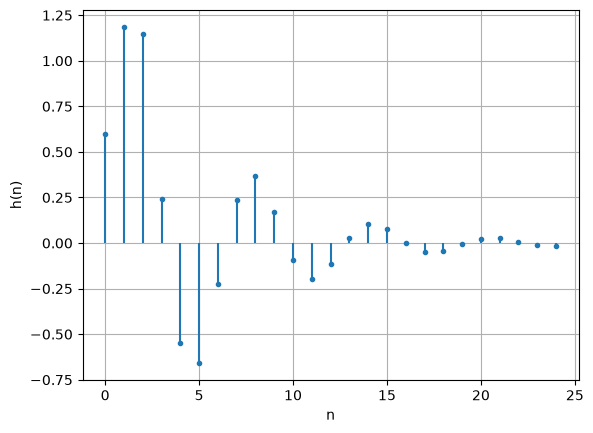

In [581]:
plt.cla()
plt.stem(range(len(h)), h, basefmt=" ", markerfmt=".")
plt.xlabel("n")
plt.ylabel("h(n)")
plt.grid(True)
plt.show()

Общая Формула для вычисления ИХ:
$$h(n) = \frac{b_0 \cdot \delta(n) + b_1 \cdot \delta(n - 1) + b_2 \cdot \delta(n - 2) - a_1 \cdot h(n-1) - a_2 \cdot h(n-2)}{a_0}$$

Начальные условия:

$$h(0) = \frac{b_0}{a_0} = 0.6$$

$$h(1) = \frac{b_1 - a_1 h(0)}{a_0} = 0.64272 + 0.9028 \cdot 0.6 = 1.1844 $$

Для $n \ge 2$:

$$h(n) = 0.9028 \cdot h(n-1) - 0.67 \cdot h(n-2) $$

В теории импульсная характеристика бесконечна. По аналитической формуле видно, что каждое следующее значение получается некоторой взвешенной суммой предыдущих значений ИХ. Импульсная характеристика, в теории, может бесконечно затухать (стремиться к нулю), не достигая нуля.

### п.2

Воздействие -- прямоугольный импульс. Используя свертку с ИХ можно вычислить реакцию $y$:

In [582]:
# прямоугольный импульс
def calc_x():
    x = [0.0] * N2
    
    for n in range(N2):
        x[n] = 1 if (0 <= n < round(N2/2)) else 0
    
    return x

def convolution(a, b):
    Na, Nb = len(a), len(b)
    N = Na + Nb - 1
    y = [0.0] * N
    for n in range(N):
        for k in range(Na):
            if 0 <= n - k < Nb:
                y[n] += a[k] * b[n - k]
    return y

x = calc_x()
y1 = convolution(x, h)

print(f"y1(n) = {y1}")

y1(n) = [0.6, 1.7844000000000002, 2.9316763200000002, 3.173889381696, 2.6238841993951487, 1.96505676947762, 1.7387708378896458, 1.9758942768967667, 2.341580891796338, 2.5128500635929005, 2.4224618399081237, 2.2261090064618108, 2.10940177829528, 2.135594891115565, 2.2374358762412947, 2.3118285320232124, 2.3107567616288884, 2.259946087943008, 1.6147922979035925, 0.42367060762554765, -0.6994210150310627, -0.9152965994791604, -0.357717689938974, 0.2903011911741318, 0.5017547676511187, 0.26463132864399785, -0.10105528625557367, -0.2723244580521359, -0.18193623436735934, 0.014416599078953637, 0.13112382724548471, 0.10493071442519926, 0.003089729299469726, -0.07130292648244765, -0.07023115608812389, -0.019420482402243734, 0.025733307637171937, 0.03245499791521671, 0.008270300571827021, -0.018067176676075183, -0.025640903915410206, -0.014832355110987388, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


Визуализация воздействия и реакции:

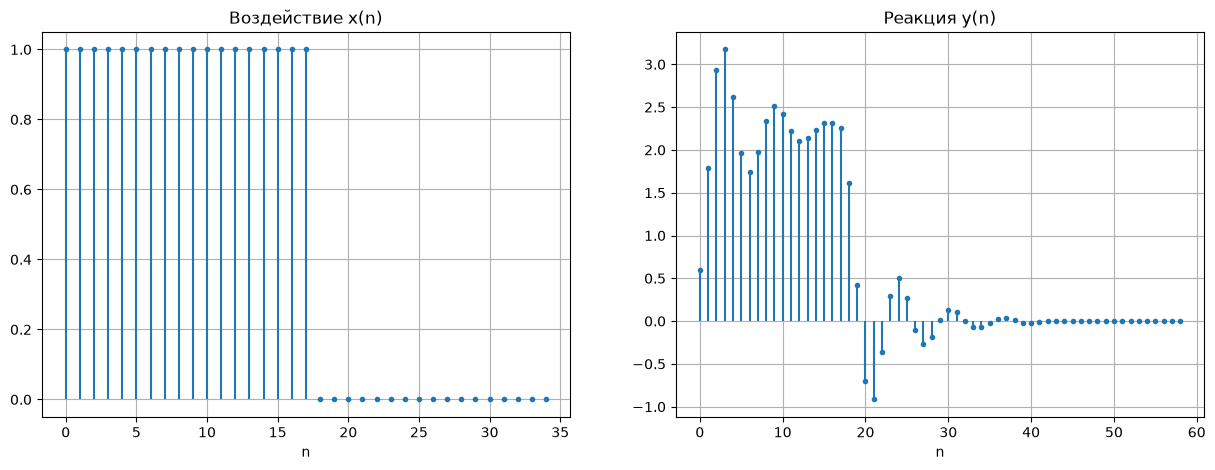

In [583]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))

axs[0].set_title("Воздействие x(n)")
axs[0].stem(range(len(x)), x, basefmt=" ", markerfmt='.')
axs[0].set_xlabel("n")
axs[0].grid(True)

axs[1].set_title("Реакция y(n)")
axs[1].stem(range(len(y1)), y1, basefmt=" ", markerfmt='.')
axs[1].set_xlabel("n")
axs[1].grid(True)

plt.show()

a. Длина последовательности $x = N_2 = 35$. При этом длина воздействия (не включая нули) -- $round(N/2) = round(17.5) = 18$

b. Длина свертки равна $N_1 + N_2 - 1 = 59$ (в теории свертка бесконечна, но значения дальше 59-го будут нулевыми)

c. Как правило интересно рассматривать реакцию на том же интервале, что и воздействие. Всё, что происходит после воздействия -- это свободные колебания системы. Если появляется необходимость их расчитать, то можно дополнить воздействие нулями. В этом случае, а также в случае единичного импульса для вычисления импульсной характеристики так и делается. Никакой полезной информации нули в конце воздействия не несут. 

### п.3

Вычисление реакции на прямоугольный импульс по рекуррентной формуле, выводимой из разностного уравнения, (как уже было сделано ранее для вычисления ИХ):

In [584]:
y2 = calc_y(b, a, x)

print(f"y2 = {y2}")

y2 = [0.6, 1.7843999999999998, 2.9316763199999993, 3.173889381695999, 2.6238841993951483, 1.96505676947762, 1.7387708378896458, 1.9758942768967667, 2.3415808917963377, 2.5128500635929, 2.4224618399081237, 2.2261090064618108, 2.10940177829528, 2.1355948911155656, 2.237435876241295, 2.311828532023212, 2.3107567616288875, 2.2599460879430078, 1.6147922979035931, 0.42367060762554876, -0.6994210150310621, -0.9152965994791606, -0.35771768993897457, 0.29030119117413145, 0.5017547676511188, 0.25848240614876195, -0.1028177780551473, -0.2660071021478575, -0.17126330052213706, 0.023608250727679192, 0.1360599401067806, 0.10701738594085648, 0.005455136155862225, -0.06677675165886143, -0.06394099262204779]


Визуализация воздействия (прямоугольный импульс $x(n)$), реакции, вычисленной с помощью свёртки ($y_1(n)$), и реакции, вычисленной по рекуррентной формуле ($y_2(n)$):

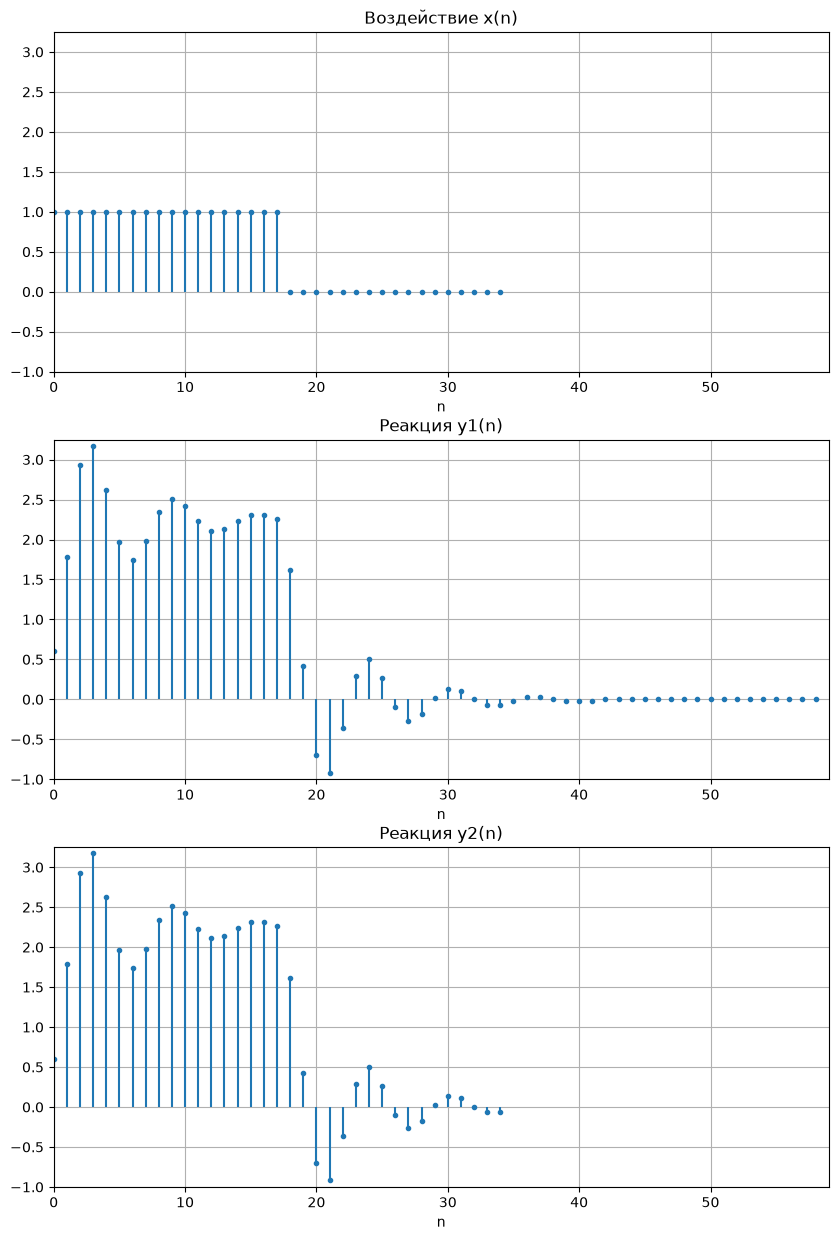

In [585]:
fig, axs = plt.subplots(3, figsize=(10, 15))

axs[0].stem(range(len(x)), x, basefmt=" ", markerfmt='.')
axs[1].stem(range(len(y1)), y1, basefmt=" ", markerfmt='.')
axs[2].stem(range(len(y2)), y2, basefmt=" ", markerfmt='.')

for i in range(3):
    axs[i].grid(True)
    axs[i].set_xlabel("n")
    axs[i].set_title(["Воздействие x(n)", "Реакция y1(n)", "Реакция y2(n)"][i])
    axs[i].set_xlim(0, 59)
    axs[i].set_ylim(-1, 3.25)

plt.show()

Длина воздействия -- 35 отсчётов включая нули или 18 отсчётов не включая нули. Соответственно, длина вычисленной реакции -- 35 отсчётов.

Построение графика разницы между $y_2(n)$ и $y_1(n)$:

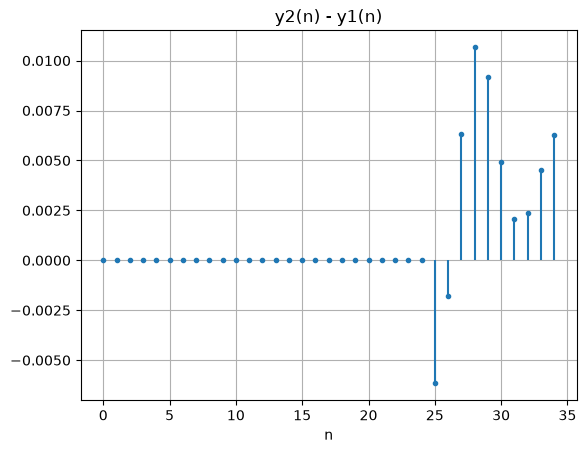

max error: 0.010672933845222277


In [586]:
plt.cla()
plt.stem(range(N2), [y2[n] - y1[n] for n in range(N2)], basefmt=" ", markerfmt='.')
plt.xlabel("n")
plt.title("y2(n) - y1(n)")
plt.grid(True)
plt.show()

print("max error:", max([abs(x - y) for x,y in zip(y2, y1)]))

Как уже было сказано выше, импульсная характеристика имеет бесконечную длину. В пункте 1 были посчитаны первые 25 ее значений. Поэтому, например, при вычислении значения реакции на 30-м отсчёте будет использована реакция только на 25 последних импульсов, более старые уже не будут иметь никакого влияния. На практике этого достаточно, потому что к этому моменту реакции на эти импульсы уже почти нет, значения околонулевые.

Вычисление рекуррентной формулой в п.3 происходит строго по рекуррентной формуле. Единственные ошибки -- это ошибки округления. Вычисления в п.2. выполнялись с конечной ИХ, поэтому содержат бОльшую ошибку.
Максимальная разница между $y_2(n)$ и $y_1(n)$ -- 0.0107. Визуально графики неразличимы.

### п.4
Числитель и знаменатель домножаются на $z^2$. Таким образом числитель и знаменатель становятся многочленами второй степени. Чтобы найти нули и полюсы необходимо найти корни этих многочленов.

Вычисление нулей и полюсов:

In [587]:
def solve_eq(A, B, C):
    D = B*B - 4*A*C
    sqrtD = cmath.sqrt(D)
    root1 = (-B + sqrtD) / (2*A)
    root2 = (-B - sqrtD) / (2*A)
    return root1, root2

num_roots   = solve_eq(b0, b1, b2)
denom_roots = solve_eq(a0, a1, a2)

print("algebraic:")
print(f"zeros: {num_roots}")
print(f"poles: {denom_roots}")

def polar(z):
    return f'{abs(z)}*exp({cmath.phase(z)}j)'

def polar_pi(z):
    return f'{abs(z)}*exp({cmath.phase(z)/math.pi}j*pi)'

print("\npolar:")
print("zeros:", *[polar(z) for z in num_roots])
print("poles:", *[polar(z) for z in denom_roots])

print("\npolar (with pi):")
print("zeros:", *[polar_pi(z) for z in num_roots])
print("poles:", *[polar_pi(z) for z in denom_roots])

algebraic:
zeros: ((-0.5356+0.7163327718316397j), (-0.5356-0.7163327718316397j))
poles: ((0.4514+0.6828162563969901j), (0.4514-0.6828162563969901j))

polar:
zeros: 0.8944271909999159*exp(2.2128220068545104j) 0.8944271909999159*exp(-2.2128220068545104j)
poles: 0.8185352771872451*exp(0.9866674921168043j) 0.8185352771872451*exp(-0.9866674921168043j)

polar (with pi):
zeros: 0.8944271909999159*exp(0.7043631211468465j*pi) 0.8944271909999159*exp(-0.7043631211468465j*pi)
poles: 0.8185352771872451*exp(0.31406601711694615j*pi) 0.8185352771872451*exp(-0.31406601711694615j*pi)


Связь между алгебраической ($z = x + jy$) и показательной ($z = r \cdot \exp(\phi j)$) формами:

$r = \sqrt{x^2 + y^2}$, $\phi = atan2(y,x)$, где

$
atan2(y, x) =
\left\{
\begin{aligned}
& arctg\frac{y}{x}, & x > 0, y > 0 \\
& \pi - arctg\left|\frac{y}{x}\right|, & x < 0, y > 0 \\
& \pi + arctg\left|\frac{y}{x}\right|, & x < 0, y < 0 \\
& 2\pi + arctg\left|\frac{y}{x}\right|, & x > 0, y < 0 \\
\end{aligned}
\right.
$

В обратную сторону:

$x = r \cos \phi$, $y = r \sin \phi$

Передаточная функция в виде произведения простейших множителей:
$$
H(z) = \frac{b_0 (1 - z_1 z^{-1})(1 - z_2 z^{-1})}{a_0 (1 - p_1 z^{-1})(1 - p_2 z^{-1})}
= 0.6 \frac {(1 - 0.8944 e^{0.7044 j \pi} \cdot z^{-1}) (1 - 0.8944 e^{-0.7044 j \pi} \cdot z^{-1})}
            {(1 - 0.8185 e^{0.3141 j \pi} \cdot z^{-1}) (1 - 0.8185 e^{-0.3141 j \pi} \cdot z^{-1})}
$$

### п.5

Построение карты нулей и полюсов:

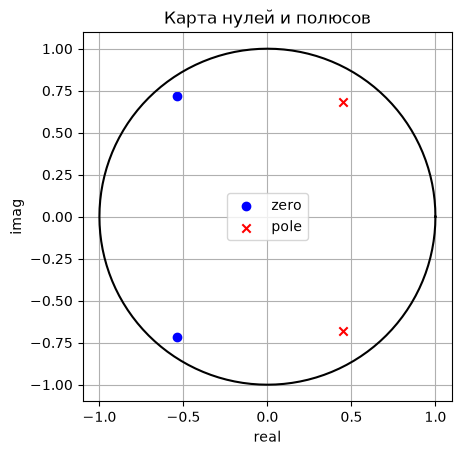

In [588]:
plt.cla()
plt.plot([math.cos(x*2*math.pi/128) for x in range(129)], [math.sin(x*2*math.pi/128) for x in range(129)], color="black")
plt.scatter([num_roots[0].real],   [num_roots[0].imag],   label="zero", marker="o", color="blue")
plt.scatter([num_roots[1].real],   [num_roots[1].imag],                 marker="o", color="blue")
plt.scatter([denom_roots[0].real], [denom_roots[0].imag], label="pole", marker="x", color="red")
plt.scatter([denom_roots[1].real], [denom_roots[1].imag],               marker="x", color="red")
plt.xlabel("real")
plt.ylabel("imag")
plt.title("Карта нулей и полюсов")
plt.grid(True)
plt.gca().set_aspect('equal')
plt.legend()
plt.show()

a. Рекурсивное звено устойчиво, т.к. полюса по абсолютной величине меньше единицы (полюса внутри единичной окружности)

b. Совпадают

### п.6

Вычисление АЧХ и ФЧХ:

max A   = 4.602703860761441 when w = 0.30078125*pi
min A   = 0.04973273617179566 when w = 0.7089843750000001*pi


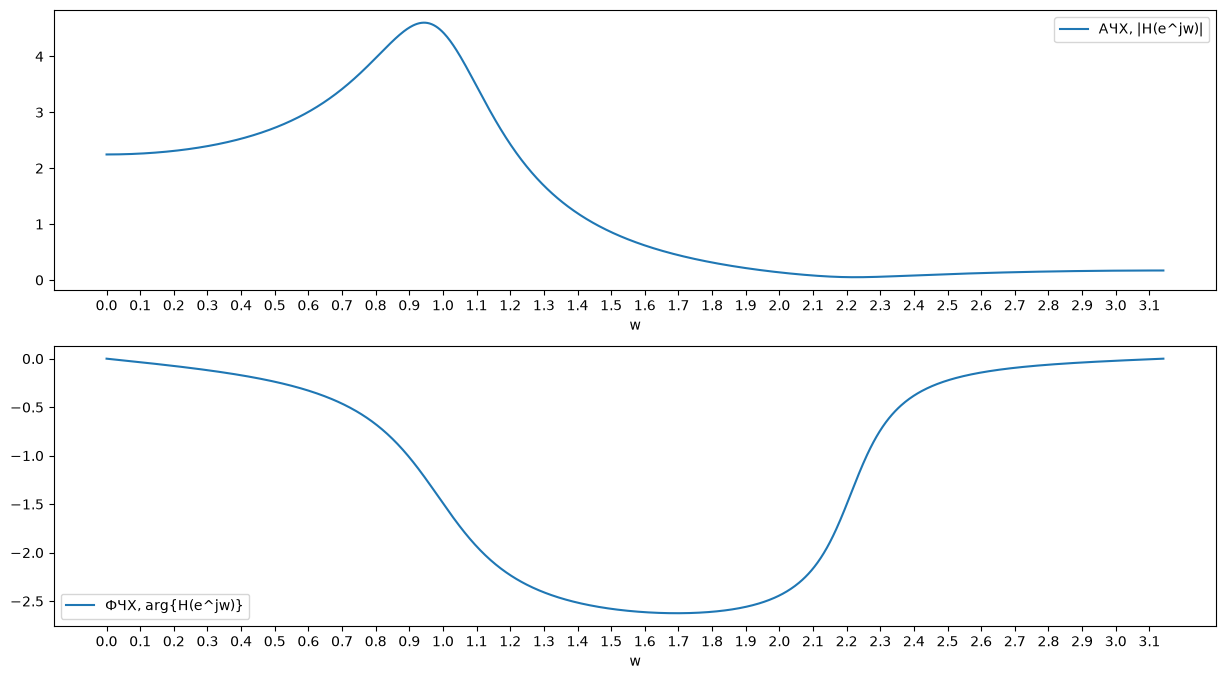

In [589]:
A_list   = []
phi_list = []
w_list   = [x/1024*math.pi for x in range(1024+1)]

for w in w_list:
    z = cmath.exp(1j * w)

    num = b0 + b1 / z + b2 / (z*z)
    den = 1.0 + a1 / z + a2 / (z*z)
    H = num / den

    A_list.append(abs(H))
    phi_list.append(cmath.phase(H))

def argmax(L): return max(list(range(len(L))), key=lambda x: L[x])
def argmin(L): return min(list(range(len(L))), key=lambda x: L[x])

argmax_A   = argmax(A_list)
argmin_A   = argmin(A_list)

print(f"max A   = {A_list[argmax_A]} when w = {w_list[argmax_A]/math.pi}*pi")
print(f"min A   = {A_list[argmin_A]} when w = {w_list[argmin_A]/math.pi}*pi")

fig, axs = plt.subplots(2, figsize=(15, 8))
axs[0].plot(w_list, A_list,   label="АЧХ, |H(e^jw)|")
axs[1].plot(w_list, phi_list, label="ФЧХ, arg{H(e^jw)}")

for i in range(2):
    axs[i].set_xlabel("w")
    axs[i].set_xticks([x/10 for x in range(3*10 + 2)])
    axs[i].legend()

plt.show()

a. Границы основной полосы частот -- $[0, \pi]$

b. Точка максимума АЧХ (при $\phi \approx 0.3 \pi$) соответствует полюсам передаточной функции. Точка минимума АЧХ (при $\phi \approx 0.7 \pi$) соответствует нулям передаточной функции.

c. Скачка фазы нет.

d. Сильнее всего подавляются в реакции частоты в районе $0.7 \pi$ и более. т.е. высокие.

### п.7

Вычисление АЧХ и ФЧХ в шкале частот $f$ при частоте дискретизации $f_d$:

max A   = 4.602703860761441 when w = 239.35411363429574*pi
min A   = 0.04973273617179566 when w = 564.19183928084*pi


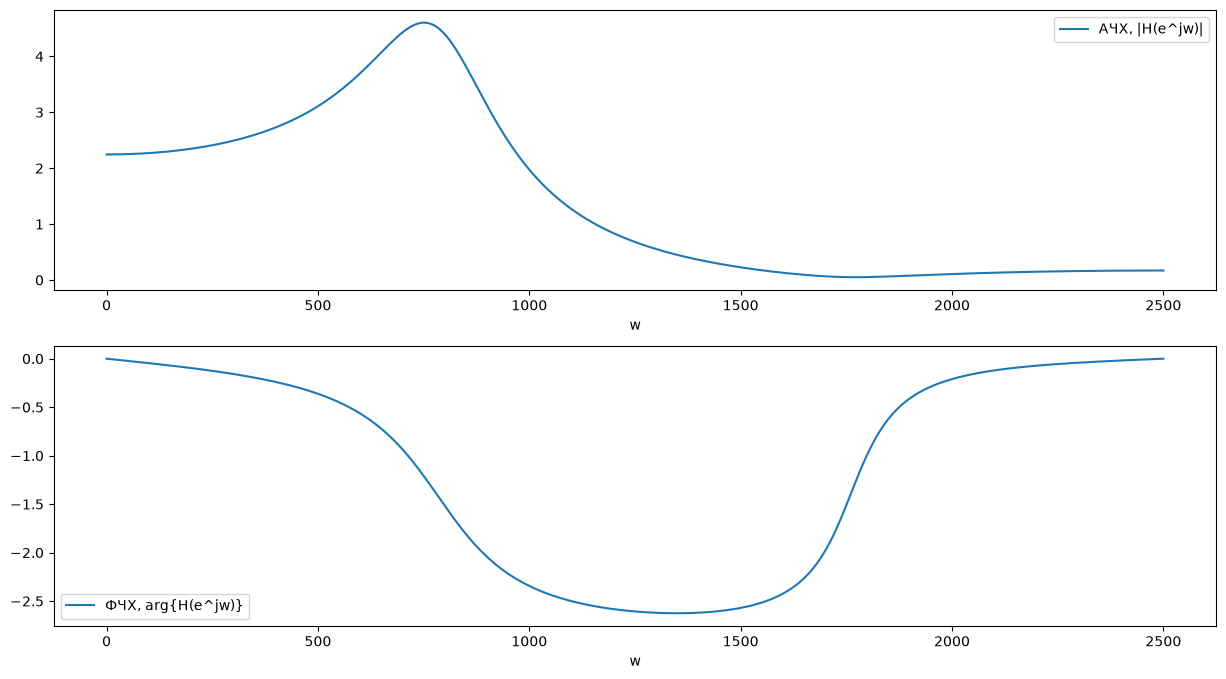

In [590]:
A_list    = []
phi_list  = []
freq_list = [x/1024*fd/2 for x in range(1024+1)]

for f in freq_list:
    z = cmath.exp(1j * 2 * math.pi * f / fd)

    num = b0 + b1 / z + b2 / (z*z)
    den = 1.0 + a1 / z + a2 / (z*z)
    H = num / den

    A_list.append(abs(H))
    phi_list.append(cmath.phase(H))

argmax_A   = argmax(A_list)
argmin_A   = argmin(A_list)

print(f"max A   = {A_list[argmax_A]} when w = {freq_list[argmax_A]/math.pi}*pi")
print(f"min A   = {A_list[argmin_A]} when w = {freq_list[argmin_A]/math.pi}*pi")

fig, axs = plt.subplots(2, figsize=(15, 8))
axs[0].plot(freq_list, A_list,   label="АЧХ, |H(e^jw)|")
axs[1].plot(freq_list, phi_list, label="ФЧХ, arg{H(e^jw)}")

for i in range(2):
    axs[i].set_xlabel("w")
    axs[i].legend()

plt.show()

a. Границы основной полосы частот -- $[0, f_d/2]$ Гц = $[0, 2500]$ Гц.

b. Связь между нормированной частотой и абсолютной: 
$$f = \frac{\hat w \cdot f_d}{2\pi}$$
$$\hat w = \frac{2 \pi f}{f_d}$$

## Часть 2

Вариант 5. Вычисление значений переменных, необходимых для выполнения задания:

In [591]:
Nvar = 5
N = 64
fd = 2000 * ((Nvar % 5) + 1)
T = 1/fd
A1 = 1 + 0.01 * Nvar
A2 = 2*A1
f1 = fd / 8
f2 = 1.5 * f1

print(Nvar, N, fd, T, A1, A2, f1, f2)

5 64 2000 0.0005 1.05 2.1 250.0 375.0


### п.1

Вычисление последовательности x(n). Визуализация в в шкале дискретного и дискретного нормированного времени:

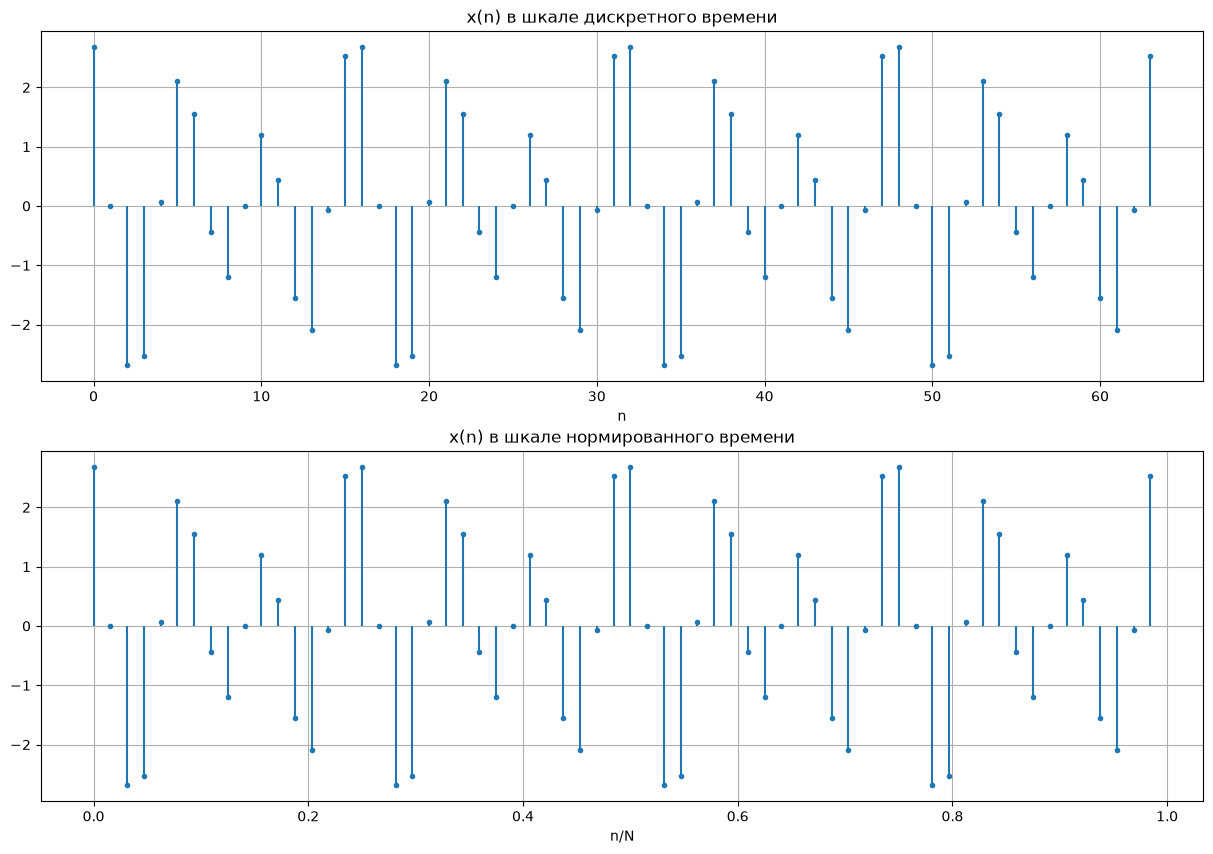

In [592]:
ns      = [x for x in range(N)]
ns01    = [x/N for x in ns]
ns_pi   = [x/N*2*math.pi for x in ns] 
ns_freq = [x/N*fd for x in ns]

def calc_x(nT):
    return A1*math.cos(2*math.pi*f1*nT + math.pi/4) + A2*math.cos(2*math.pi*f2*nT + math.pi/8)

xs = [0 for _ in range(N)]
for n in ns:
    xs[n] = calc_x(n*T)

fig, axs = plt.subplots(2, figsize=(15, 10))
axs[0].stem(ns,   xs, basefmt=" ", markerfmt='.')
axs[1].stem(ns01, xs, basefmt=" ", markerfmt='.')
axs[0].grid(True)
axs[1].grid(True)
axs[0].set_xlabel("n")
axs[1].set_xlabel("n/N")
axs[0].set_title("x(n) в шкале дискретного времени")
axs[1].set_title("x(n) в шкале нормированного времени")
plt.show()

### п.2

Выполнение дискретного преобразования Фурье последовательности $x$:

In [593]:
def fourier(x):
    N = len(x)
    X = [0.0] * N
    for k in range(N):
        for n in range(N):
            X[k] += x[n] * cmath.exp(-1j * 2 * math.pi / N * n * k)
    return X

X = fourier(xs)
print(f"X = {X}")

X = [(-1.2434497875801753e-14+0j), (-2.9753977059954195e-14-4.524158825347513e-15j), (-4.04121180963557e-14-1.9040324872321435e-14j), (-4.618527782440651e-14-1.509903313490213e-14j), (-5.773159728050814e-14-7.260858581048524e-14j), (2.930988785010413e-14-2.6867397195928788e-14j), (4.4853010194856324e-14-9.547918011776346e-15j), (2.6867397195928788e-14-6.750155989720952e-14j), (23.758787847868003+23.75878784786798j), (5.551115123125783e-14+1.176836406102666e-14j), (-4.75175454539567e-14-7.993605777301127e-15j), (-2.864375403532904e-14-1.9095836023552692e-14j), (62.08470458475847+25.71632665493399j), (2.2870594307278225e-14-7.993605777301127e-15j), (1.637578961322106e-14+1.865174681370263e-14j), (2.9531932455029164e-14-5.551115123125783e-14j), (6.289791975431629e-14-3.68594044175552e-14j), (1.6930901125533637e-15+5.595524044110789e-14j), (-7.172040739078511e-14-3.730349362740526e-14j), (5.384581669432009e-14-4.529709940470639e-14j), (6.827871601444713e-14+1.687538997430238e-14j), (4.9515

Вычисление обратного дискретного преобразования Фурье от вычисленного ранее ДПФ:

In [594]:
def inv_fourier(X):
    N = len(X)
    x = [0.0] * N
    for n in range(N):
        for k in range(N):
            x[n] += X[k] * cmath.exp(1j * 2 * math.pi / N * n * k)
        x[n] /= N
    return x

xs2 = inv_fourier(X)

Визуализация исходного дискретного сигнала и сигнала, полученного обратным дискретным преобразованием Фурье дискретного преобразования Фурье $x$:

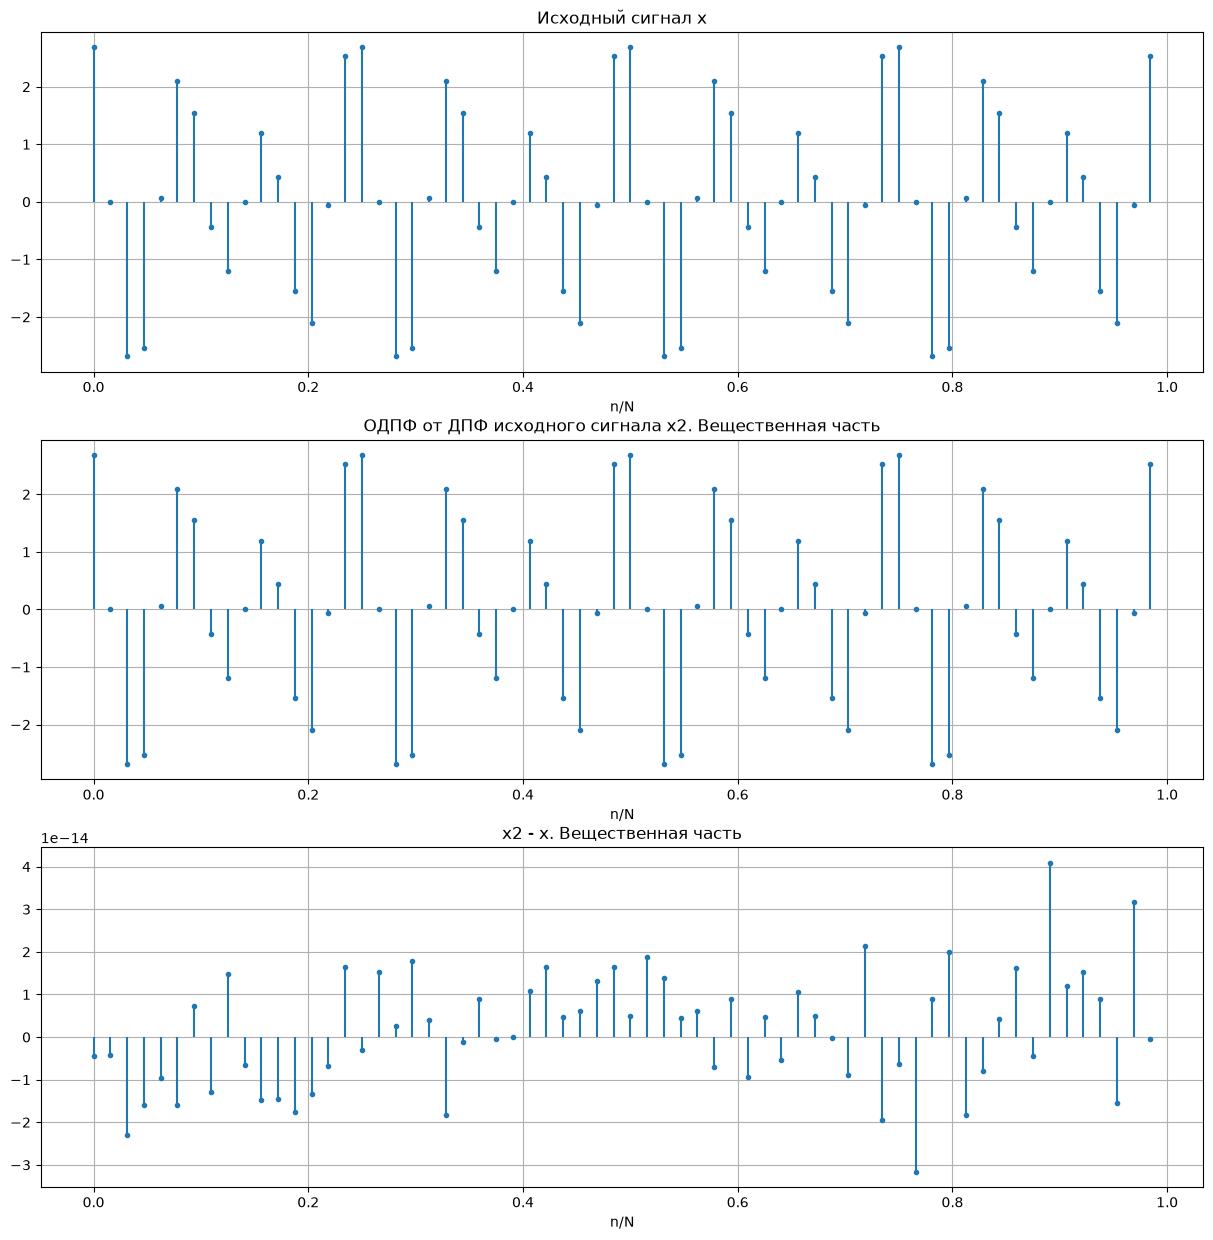

In [595]:
fig, axs = plt.subplots(3, figsize=(15, 15))
axs[0].set_title("Исходный сигнал x")
axs[0].stem(ns01, [z.real for z in xs],  basefmt=" ", markerfmt='.')
axs[1].set_title("ОДПФ от ДПФ исходного сигнала x2. Вещественная часть")
axs[1].stem(ns01, [z.real for z in xs2], basefmt=" ", markerfmt='.', )
axs[2].set_title("x2 - x. Вещественная часть")
axs[2].stem(ns01, [(xs2[n] - xs[n]).real for n in ns], basefmt=" ", markerfmt='.')

for i in range(3):
    axs[i].grid(True)
    axs[i].set_xlabel("n/N")
    
plt.show()

In [596]:
rmse = math.sqrt(sum([(abs(xs2[n]) - abs(xs[n]))**2 for n in ns]) / N)
print(f"RMSE: {rmse}")

RMSE: 1.342881653175942e-14


ОДПФ восстанавливает исходный сигнал по ДПФ со среднеквадратичной ошибкой порядка $10^{-14}$

### п.3

Вычисление и визуализация амплитудного и фазового спектров в нормированных и абсолютных частотах:
(оранжевым цветом на фазовых спектрах помечены частоты с ненулевыми амплитудами)

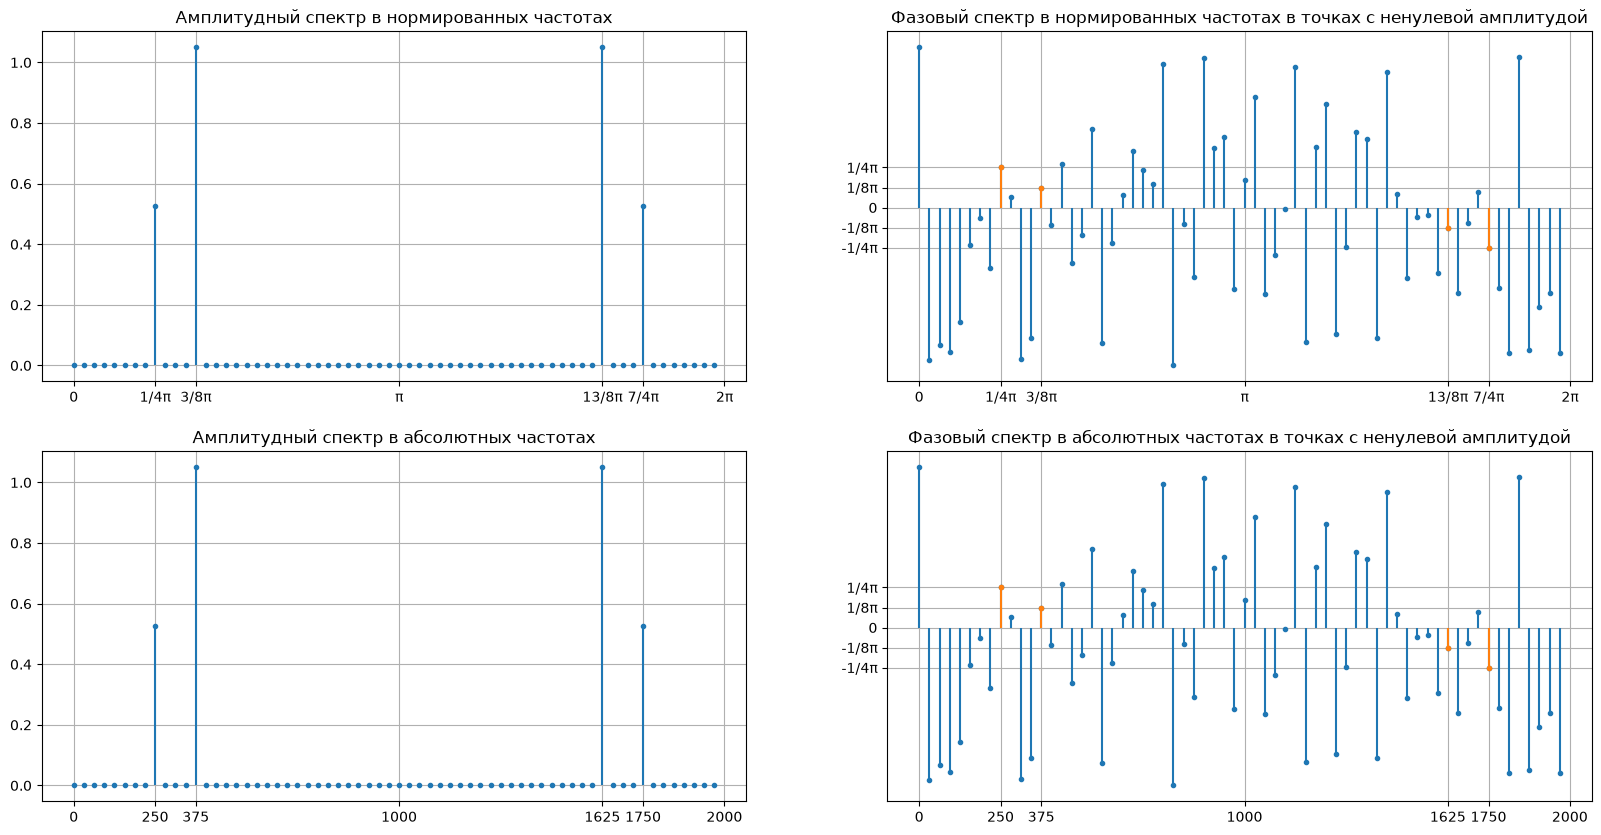

In [597]:
fig, axs = plt.subplots(2, 2, figsize=(20, 10))

pi = math.pi
pi_ticks  = [0, pi/4, 3/8*pi, pi, 13/8*pi, 7/4*pi, 2*pi]
pi_labels = ["0", "1/4π", "3/8π", "π", "13/8π", "7/4π", "2π"]
abs_ticks = [0, 250, 375, 1000, 2000-375, 2000-250, 2000]

phase_labels = ["-1/4π", "-1/8π", "0", "1/8π", "1/4π"]
phase_ticks  = [-pi/4, -pi/8, 0, pi/8, pi/4]

axs[0,0].set_title("Амплитудный спектр в нормированных частотах")
axs[0,0].stem(ns_pi, [abs(z)/N for z in X], basefmt=" ", markerfmt='.')
axs[0,0].set_xticks(pi_ticks, pi_labels)

axs[0,1].set_title("Фазовый спектр в нормированных частотах в точках с ненулевой амплитудой")
axs[0,1].stem(ns_pi, [cmath.phase(X[n]) for n in range(N)], basefmt=" ", markerfmt='.')
axs[0,1].stem([ns_pi[n] for n in range(N) if abs(X[n]) > 1e-12], [cmath.phase(X[n]) for n in range(N) if abs(X[n]) > 1e-12], basefmt=" ", markerfmt='.', linefmt="C1")
axs[0,1].set_xticks(pi_ticks, pi_labels)
axs[0,1].set_yticks(phase_ticks, phase_labels)

axs[1,0].set_title("Амплитудный спектр в абсолютных частотах")
axs[1,0].stem(ns_freq, [abs(z)/N for z in X], basefmt=" ", markerfmt='.')
axs[1,0].set_xticks(abs_ticks)

axs[1,1].set_title("Фазовый спектр в абсолютных частотах в точках с ненулевой амплитудой")
axs[1,1].stem(ns_freq, [cmath.phase(X[n]) for n in range(N)], basefmt=" ", markerfmt='.')
axs[1,1].stem([ns_freq[n] for n in range(N) if abs(X[n]) > 1e-12], [cmath.phase(X[n]) for n in range(N) if abs(X[n]) > 1e-12], basefmt=" ", markerfmt='.', linefmt="C1")
axs[1,1].set_xticks(abs_ticks)
axs[1,1].set_yticks(phase_ticks, phase_labels)

for i in range(4):
    axs[i%2, i//2].grid(True)
plt.show()


a. Связь дискретного нормированного времени с дискретным временем: $\hat n = n / N$. т.е. $n = 0, 1, ..., N-1 \iff \hat n = 0, ..., (N-1)/N$.

b. Связь частоты в герцах с нормированной частотой: $\hat w = \frac{2 \pi \cdot f}{f_d}$, $f = \frac{\hat w \cdot f_d}{2 \pi}$

c. Наблюдается 4 пика на амплитудном спектре, симметричных относительно $\pi$. Исходная функция $x$:
$$
\begin{aligned}
A_1 \cos(2 \pi f_1 n T + \pi / 4) + A_2 \cos(2 \pi f_2 n T + \pi / 8) = & \\
1.05 \cos(2 \pi \cdot 250 \cdot 0.0005 \cdot n + \pi/4) + 2.1 \cos(2 \pi \cdot 375 \cdot 0.0005 \cdot n + \pi/8) = & \\
1.05 \cos(1/4 \pi \cdot n + \pi/4) + 2.1 \cos(3/8 \pi \cdot n + \pi/8) = & \\
\frac{1.05}{2} e^{1/4 \pi j n + \pi/4} + \frac{1.05}{2} e^{-1/4 \pi j n - \pi/4} + \frac{2.1}{2} e^{3/8 \pi j n + \pi/8} + \frac{2.1}{2} e^{-3/8 \pi j n - \pi/8} &
\end{aligned}
$$

Два косинуса разбиваются в сумму четырех комплексных экспонент. Каждая экспонента соответствует пику на амплитудном спектре. Соответственно значения на амплитудном спектре совпадают с амплитудами этих четырех экспонент. А на фазовом спектре для этих экспонент корректно определена фаза.

### п.4

Коэффициент ДПФ $X(k)$ -- сумма по всем N отсчётам, поэтому его модуль пропорционален длине последовательности. Деление $|X(k)|$ на $N$ даёт амплитуду, не зависящую от длины записи. Для периодической последовательности эти величины $A(k) = |X(k)|/N$ -- это коэффициенты её ряда Фурье

Сравнение модуля ДПФ конечной последовательности и амплитудного спектра периодической последовательности:

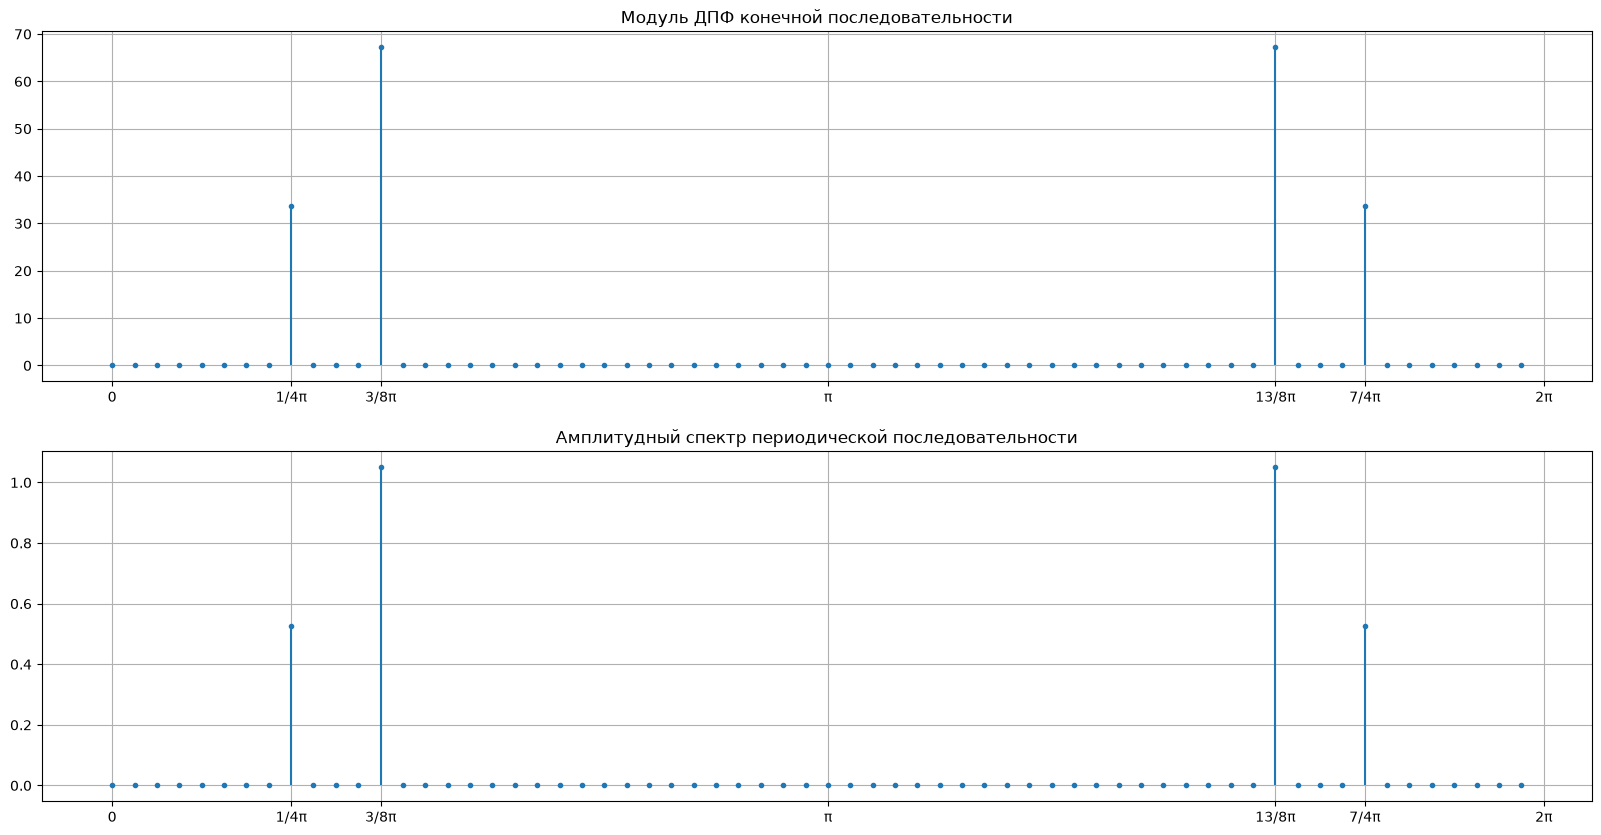

In [598]:
fig, axs = plt.subplots(2, figsize=(20, 10))

pi = math.pi
pi_ticks  = [0, pi/4, 3/8*pi, pi, 13/8*pi, 7/4*pi, 2*pi]
pi_labels = ["0", "1/4π", "3/8π", "π", "13/8π", "7/4π", "2π"]
abs_ticks = [0, 250, 375, 1000, 2000-375, 2000-250, 2000]

phase_labels = ["-1/4π", "-1/8π", "0", "1/8π", "1/4π"]
phase_ticks  = [-pi/4, -pi/8, 0, pi/8, pi/4]

axs[0].set_title("Модуль ДПФ конечной последовательности")
axs[0].stem(ns_pi, [abs(z) for z in X], basefmt=" ", markerfmt='.')
axs[0].set_xticks(pi_ticks, pi_labels)
axs[0].grid(True)

axs[1].set_title("Амплитудный спектр периодической последовательности")
axs[1].stem(ns_pi, [abs(z)/N for z in X], basefmt=" ", markerfmt='.')
axs[1].set_xticks(pi_ticks, pi_labels)
axs[1].grid(True)

plt.show()

$|X(k)|$ -- модуль ДПФ конечной последовательности, $A_k$ -- амплитудный спектр периодической последовательности

$$A_k = \frac{|X(k)|}{N}$$

### п.5

Восстановление исходного сигнала на временной сетке с высоким разрешением:

In [599]:
def Xa(k):
    global X
    return X[k] if (0 <= k <= (N//2 - 1)) else X[N+k]

dt = 0.25 * T
t = [float(x) for x in np.arange(0, (N - 1)*T + dt, dt)]

def inv_fourier(ts):
    x = []
    for t in ts:
        xt = 0.0
        for k in range(-N//2, N//2):
            xt += Xa(k) * cmath.exp(1j * 2 * math.pi / (N * T) * k * t)
        x.append(xt / N)
    return x

xa = inv_fourier(t)

Построение графиков дискретизированного сигнала, исходного аналогового сигнала и сигнала, восстановленного из ДПФ: 

max error: 3.928230724119534e-14


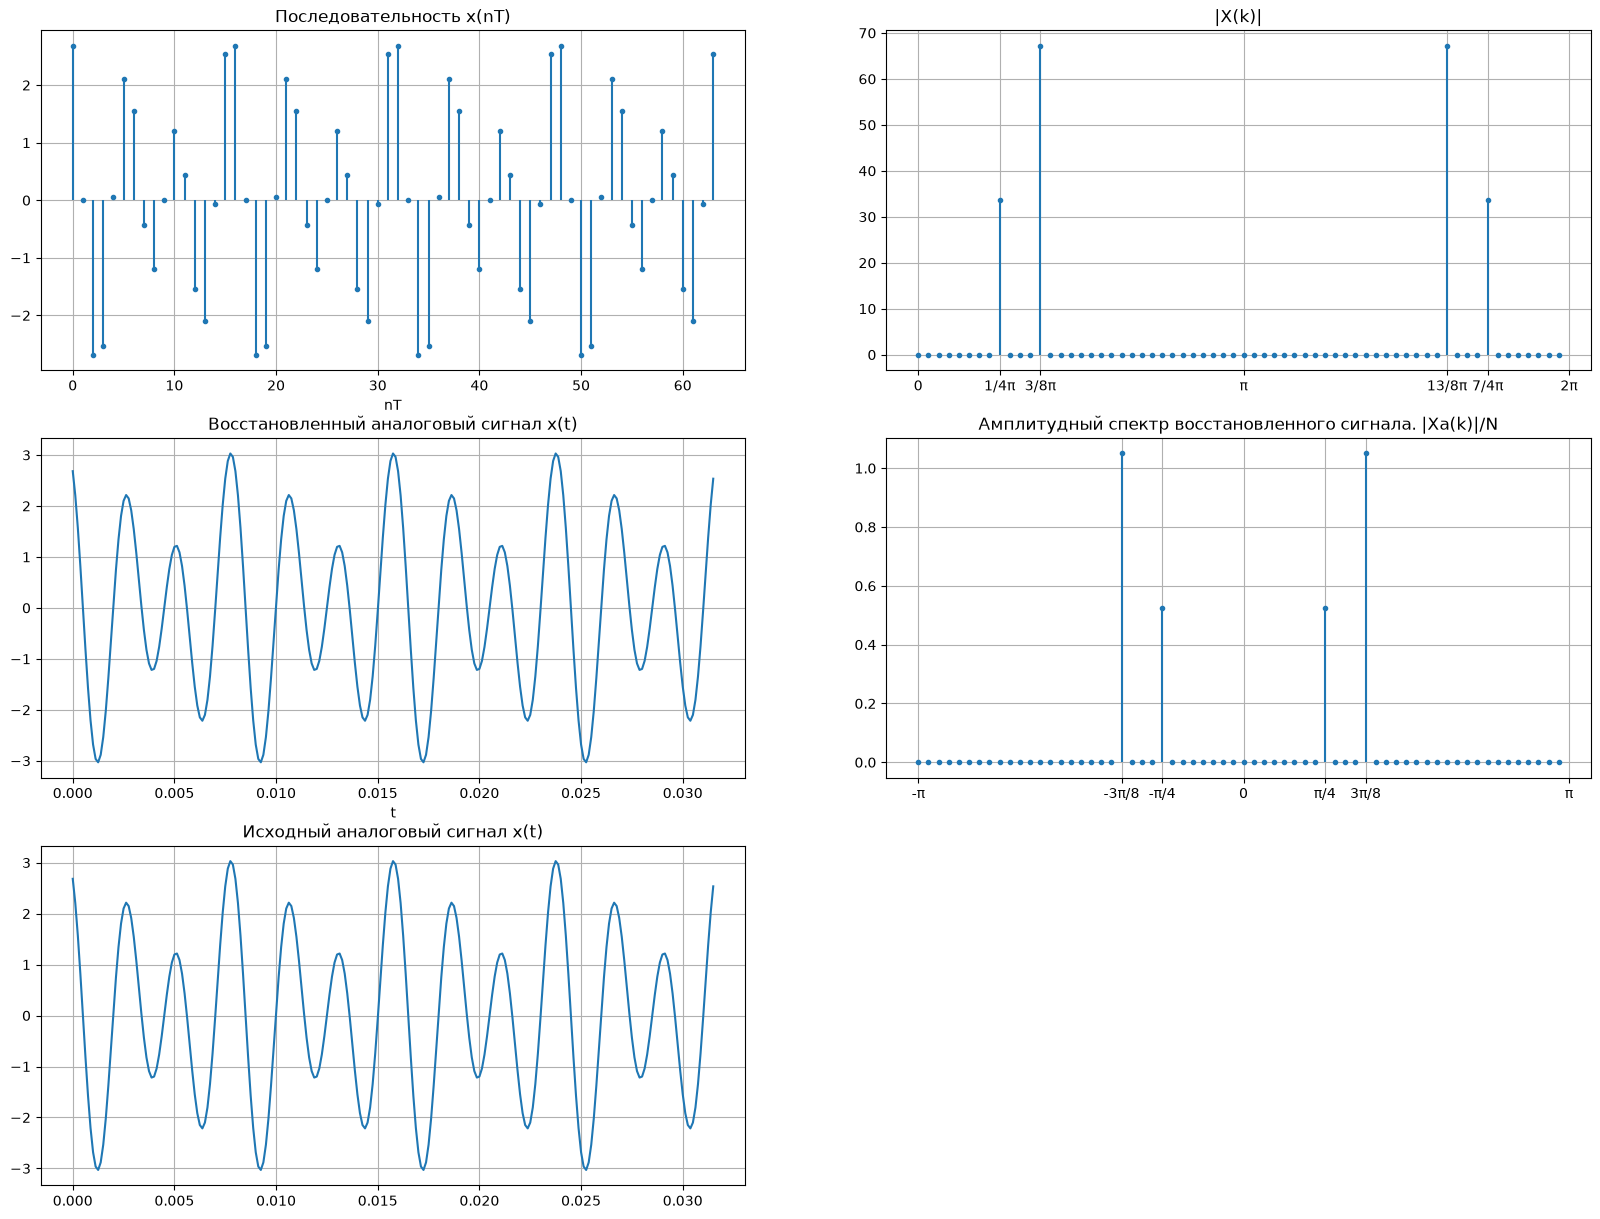

In [600]:
fig, axs = plt.subplots(3, 2, figsize=(20, 15))

axs[0,0].set_title("Последовательность x(nT)")
axs[0,0].set_xlabel("nT")
axs[0,0].stem(ns, xs, basefmt=" ", markerfmt='.')

axs[0,1].set_title("|X(k)|")
axs[0,1].stem(ns_pi, [abs(z) for z in X], basefmt=" ", markerfmt='.')
axs[0,1].set_xticks(pi_ticks, pi_labels)

axs[1,0].set_title("Восстановленный аналоговый сигнал x(t)")
axs[1,0].set_xlabel("t")
axs[1,0].plot(t, [x.real for x in xa])

ns2 = range(-N//2, N//2)
ns_pi2 = [x/N*2*math.pi for x in ns2]
pi_ticks2 = [-pi, -3*pi/8, -pi/4, 0, pi/4, 3*pi/8, pi]
pi_labels2 = ["-π", "-3π/8", "-π/4", "0", "π/4", "3π/8", "π"]

axs[1,1].set_title("Амплитудный спектр восстановленного сигнала. |Xa(k)|/N")
axs[1,1].stem(ns_pi2, [abs(Xa(k))/N for k in ns2], basefmt=" ", markerfmt='.')
axs[1,1].set_xticks(pi_ticks2, pi_labels2)

x_analog = [calc_x(tt) for tt in t]
axs[2,0].set_title("Исходный аналоговый сигнал x(t)")
axs[2,0].plot(t, x_analog)

axs[2,1].axis("off")

for i in range(6):
    axs[i%3,i//3].grid(True)

print("max error:", max([ abs(x - y) for x,y in zip(x_analog, xa) ]))

### п. 6

a. Амплитудный спектр восстановленного сигнала получается делением модуля ДПФ на N и сдвигом второй половины спектра на $2\pi$ (в нормированных частотах) влево.


b. Сигналы визуально неразличимы: $\max_t |x_a(t) - x(t)| \approx 3.9 \cdot 10^{-14}$ -- погрешность уровня машинной точности. Впрочем, этого и стоило ожидать. Сигнал состоит ровно из тех четырёх комплексных экспонент, которые видно на амплитудном спектре, т.е. не было пропущено ни одной компоненты сигнала. К тому же в исходном сигнале обе частоты косинусов (250 Гц и 375 Гц) не превышают частоты Найтквиста $f_d/2 = 1000$ Гц.

### п. 7

Равенство Парсеваля:

In [601]:
E_time = sum(abs(x) ** 2 for x in xs)
E_freq = sum(abs(z) ** 2 for z in X) / N
print(f"E_time = {E_time:.16f}")
print(f"E_freq = {E_freq:.16f}")
print(f"error  = {E_time - E_freq}")

E_time = 176.4000000000000057
E_freq = 176.3999999999999204
error  = 8.526512829121202e-14


Вычисленные энергии во временной и в частотной областях практически не отличаются. Ошибка порядка $10^{-14}$. Это ошибки машинного округления. Равенство соблюдается. 


## Вывод


Исследовано рекурсивное звено 2-го порядка. Импульсная характеристика бесконечна и для устойчивого звена затухает; реакция на прямоугольный импульс найдена двумя способами -- свёрткой (с усечённой до $N_1 = 25$ ИХ) и рекуррентным разностным уравнением. Расхождение $\max|y_2 - y_1| = 0.0107$ объясняется отброшенным хвостом ИХ. Нули ($r = 0.894$, $\arg = \pm 0.704\pi$) и полюсы ($r = 0.819$, $\arg = \pm 0.314\pi$) образуют комплексно-сопряжённые пары. Все полюсы внутри единичной окружности -- звено устойчиво. АЧХ имеет максимум вблизи аргумента полюсов ($A_{\max} = 4.6$ на $0.30\pi$) и минимум вблизи аргумента нулей ($A_{\min} = 0.05$ на $0.71\pi$, причем не ноль). ФЧХ непрерывна, скачка нет. Звено преимущественно подавляет высокие частоты.

Для последовательности из двух косинусоид с нормированными частотами $\pi/4$ и $3\pi/8$ (точное попадание отсчёты 8 и 12) ОДПФ восстанавливает последовательность с ошибкой порядка $10^{-14}$. Амплитудный спектр -- четыре линии $A_1/2 = 0.525$ и $A_2/2 = 1.05$ с фазами $\pm\pi/4$, $\pm\pi/8$; модуль ДПФ конечной последовательности отличается от амплитудного спектра периодической только нормировкой на $N$. Аналоговый сигнал, восстановленный рядом Фурье по отсчётам ДПФ, совпадает с исходным до $3.9 \cdot 10^{-14}$. Равенство Парсеваля выполняется ($E = 176.4$ в обеих областях).